# TP2_3 — Conditional WGAN-GP on CelebA

## 1. Conditional GANs

Un **Conditional GAN** conditionne à la fois le générateur et le critic sur une information de label.  
Au lieu de générer des images quelconques, on peut **imposer un attribut** (ex: `Blond_Hair` = 0 ou 1).

**Différences par rapport à un GAN standard :**
- Le label est passé **dans le générateur et le critic**.
- Le générateur apprend à produire des images **qui correspondent au label**.
- Le critic vérifie si l'image est réelle **et** si elle correspond au label.

## 2. Imports & Hyperparamètres

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import pandas as pd

# -----------------------------
# HYPERPARAMETERS
# -----------------------------
IMAGE_SIZE    = 64
CHANNELS      = 3
LABEL_DIM     = 2          # 'Blond_Hair' => 2 classes: 0 ou 1 (one-hot)
BATCH_SIZE    = 32         # Réduit pour le sous-ensemble de 300 images
Z_DIM         = 32
LEARNING_RATE = 0.00005
BETA1         = 0.5
BETA2         = 0.999
EPOCHS        = 20
CRITIC_STEPS  = 3
GP_WEIGHT     = 10.0
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cpu


## 3. Préparer le Dataset (CelebA — 300 images)

Les 300 images et le CSV ont déjà été extraits dans `../celeba_subset/` par le TP1_3.

In [2]:
# CSV contenant les attributs (ex: 'Blond_Hair')
ATTR_CSV = "../celeba_subset/list_attr_celeba.csv"
df = pd.read_csv(ATTR_CSV)

# Attribut cible
LABEL = "Blond_Hair"

# Convertir de [-1, +1] (convention CelebA) vers [0, 1]
df[LABEL] = df[LABEL].apply(lambda x: 1 if x == 1 else 0)

# Filtrer uniquement les 300 images extraites
img_folder = "../celeba_subset/img_align_celeba"
extracted_names = set(os.listdir(img_folder))
df = df[df["image_id"].isin(extracted_names)].reset_index(drop=True)

img_fnames = df["image_id"].tolist()
labels     = df[LABEL].tolist()

print(f"{len(img_fnames)} images disponibles")
print(f"Blond: {sum(labels)}, Non-blond: {len(labels)-sum(labels)}")
print(img_fnames[:5])
print(labels[:5])
df.head()

300 images disponibles
Blond: 37, Non-blond: 263
['000001.jpg', '000002.jpg', '000003.jpg', '000004.jpg', '000005.jpg']
[0, 0, 0, 0, 0]


,image_id,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
0,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,-1,1,1,-1,1,-1,1,-1,-1,1
1,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
2,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,1
3,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,1,-1,1,1,-1,1
4,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1


In [3]:
# -----------------------------
# DATASET (Conditional)
# -----------------------------
class CelebAConditionalDataset(Dataset):
    """
    Retourne des paires (image, label) où label est 0 ou 1.
    """
    def __init__(self, root_dir, img_fnames, labels, transform=None):
        self.root_dir   = root_dir
        self.img_fnames = img_fnames
        self.labels     = labels
        self.transform  = transform

    def __len__(self):
        return len(self.img_fnames)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.img_fnames[idx])
        image    = torchvision.io.read_image(img_path)  # (C, H, W), uint8 0-255
        label    = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

# Transform: resize, uint8→float [0,1], normalize to [-1,1]
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ConvertImageDtype(torch.float),       # [0, 1]
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),  # [-1, 1]
])

root_dir   = img_folder
dataset    = CelebAConditionalDataset(root_dir, img_fnames, labels, transform=transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                        drop_last=True, num_workers=0)
print(f"Dataset: {len(dataset)} images — {len(dataloader)} batches/epoch")

Dataset: 300 images — 9 batches/epoch


## 4. Conditional Critic

**Principe :** On concatène le label (one-hot expansé spatialement) avec l'image.
- Image : (3, 64, 64)
- Label one-hot expansé : (2, 64, 64)
- Input critic : (3+2, 64, 64) = (5, 64, 64)

Pas de Sigmoid final (approche Wasserstein).

In [4]:
# -----------------------------
# CONDITIONAL CRITIC
# -----------------------------
class ConditionalCritic(nn.Module):
    """
    Critic pour Conditional WGAN-GP.
    - Prend des paires (image, label).
    - Le label est étendu spatialement et concaténé à l'image.
    """
    def __init__(self, img_channels=3, label_dim=2, base_features=64):
        super().__init__()
        self.img_channels = img_channels
        self.label_dim    = label_dim

        self.model = nn.Sequential(
            # Input: (img_channels + label_dim, 64, 64) = (5, 64, 64)
            nn.Conv2d(img_channels + label_dim, base_features, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            # (base_features, 32, 32) -> (base_features*2, 16, 16)
            nn.Conv2d(base_features, base_features * 2, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(base_features * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            # (base_features*2, 16, 16) -> (base_features*4, 8, 8)
            nn.Conv2d(base_features * 2, base_features * 4, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(base_features * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            # (base_features*4, 8, 8) -> (base_features*8, 4, 4)
            nn.Conv2d(base_features * 4, base_features * 8, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(base_features * 8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            # (base_features*8, 4, 4) -> (1, 1, 1)  — pas de Sigmoid
            nn.Conv2d(base_features * 8, 1, kernel_size=4, stride=1, padding=0),
            nn.Flatten(start_dim=1)   # (B, 1)
        )

    def forward(self, image, label):
        """
        image : (B, 3, 64, 64)
        label : (B,) ou (B,1) — converti en one-hot (B, label_dim)
        """
        if label.dim() == 1 or label.shape[-1] == 1:
            label = F.one_hot(label.long(), num_classes=self.label_dim).float()
        bsz       = label.size(0)
        label_img = label.view(bsz, self.label_dim, 1, 1).repeat(1, 1, IMAGE_SIZE, IMAGE_SIZE)
        x         = torch.cat([image, label_img], dim=1)   # (B, 5, 64, 64)
        return self.model(x)

## 5. Conditional Generator

**Principe :** On concatène le vecteur de bruit z avec le label one-hot → input de taille `z_dim + label_dim = 34`.

In [5]:
# -----------------------------
# CONDITIONAL GENERATOR
# -----------------------------
class ConditionalGenerator(nn.Module):
    """
    Generator pour Conditional WGAN-GP.
    - Concatène z et le label one-hot → (z_dim + label_dim, 1, 1).
    - Upsample vers (3, 64, 64).
    """
    def __init__(self, z_dim=32, label_dim=2, img_channels=3, base_features=64):
        super().__init__()
        self.z_dim     = z_dim
        self.label_dim = label_dim

        self.model = nn.Sequential(
            # Input: (z_dim + label_dim, 1, 1) = (34, 1, 1) -> (base_features*8, 4, 4)
            nn.ConvTranspose2d(z_dim + label_dim, base_features * 8, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(base_features * 8),
            nn.LeakyReLU(0.2, inplace=True),

            # (base_features*8, 4, 4) -> (base_features*4, 8, 8)
            nn.ConvTranspose2d(base_features * 8, base_features * 4, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(base_features * 4),
            nn.LeakyReLU(0.2, inplace=True),

            # (base_features*4, 8, 8) -> (base_features*2, 16, 16)
            nn.ConvTranspose2d(base_features * 4, base_features * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(base_features * 2),
            nn.LeakyReLU(0.2, inplace=True),

            # (base_features*2, 16, 16) -> (base_features, 32, 32)
            nn.ConvTranspose2d(base_features * 2, base_features, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(base_features),
            nn.LeakyReLU(0.2, inplace=True),

            # (base_features, 32, 32) -> (img_channels, 64, 64)
            nn.ConvTranspose2d(base_features, img_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()   # output in [-1, 1]
        )

    def forward(self, noise, label):
        """
        noise : (B, z_dim, 1, 1)
        label : (B,) ou (B,1) — converti en one-hot (B, label_dim, 1, 1)
        """
        if label.dim() == 1 or label.shape[-1] == 1:
            label = F.one_hot(label.long(), num_classes=self.label_dim).float()
        bsz       = label.size(0)
        label_img = label.view(bsz, self.label_dim, 1, 1)   # (B, label_dim, 1, 1)
        z_cat     = torch.cat([noise, label_img], dim=1)     # (B, z_dim + label_dim, 1, 1)
        return self.model(z_cat)

## 6. Initialiser les modèles & optimiseurs

In [6]:
# -----------------------------
# INITIALIZE MODELS
# -----------------------------
critic    = ConditionalCritic(img_channels=CHANNELS, label_dim=LABEL_DIM, base_features=64).to(DEVICE)
generator = ConditionalGenerator(z_dim=Z_DIM, label_dim=LABEL_DIM, img_channels=CHANNELS, base_features=64).to(DEVICE)
print("Conditional Critic and Generator successfully initialized!")

# -----------------------------
# OPTIMIZERS
# -----------------------------
critic_optimizer    = optim.Adam(critic.parameters(),    lr=LEARNING_RATE, betas=(BETA1, BETA2))
generator_optimizer = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))

Conditional Critic and Generator successfully initialized!


## 7. Gradient Penalty (conditionnel)

In [7]:
# -----------------------------
# GRADIENT PENALTY
# -----------------------------
def gradient_penalty(critic, real_imgs, fake_imgs, labels, device=DEVICE):
    """
    Gradient penalty pour WGAN-GP conditionnel :
    1. Interpole réel & faux
    2. Critic(interpolé, label)
    3. Pénalise si ||grad||_2 ≠ 1
    """
    bsz, C, H, W = real_imgs.shape
    alpha        = torch.rand(bsz, 1, 1, 1, device=device).expand(bsz, C, H, W)

    interpolated = real_imgs * alpha + fake_imgs.detach() * (1 - alpha)
    interpolated.requires_grad_(True)

    critic_score = critic(interpolated, labels)

    grad = torch.autograd.grad(
        inputs=interpolated,
        outputs=critic_score,
        grad_outputs=torch.ones_like(critic_score),
        create_graph=True,
        retain_graph=True
    )[0]

    grad      = grad.view(bsz, -1)
    grad_norm = grad.norm(2, dim=1)
    gp        = torch.mean((grad_norm - 1) ** 2)
    return gp

## 8. Boucle d'entraînement

- **Critic loss** : $E[\text{critic}(\text{fake}, l)] - E[\text{critic}(\text{real}, l)] + \lambda \cdot GP$
- **Generator loss** : $-E[\text{critic}(\text{fake}, l)]$

In [8]:
# -----------------------------
# TRAINING LOOP
# -----------------------------
print("Starting conditional WGAN-GP training!")
g_losses, c_losses = [], []

for epoch in range(EPOCHS):
    progress_bar = tqdm(enumerate(dataloader), total=len(dataloader),
                        desc=f"Epoch {epoch+1}/{EPOCHS}")

    for batch_idx, (real_images, labels) in progress_bar:
        real_images = real_images.to(DEVICE)
        labels      = labels.to(DEVICE)
        cur_bsz     = real_images.size(0)

        # -------------------------
        # (a) Train Critic — CRITIC_STEPS fois
        # -------------------------
        for _ in range(CRITIC_STEPS):
            noise       = torch.randn(cur_bsz, Z_DIM, 1, 1, device=DEVICE)
            fake_images = generator(noise, labels)

            critic_optimizer.zero_grad()
            critic_real = critic(real_images, labels).view(-1)
            critic_fake = critic(fake_images.detach(), labels).view(-1)

            wass_distance = torch.mean(critic_fake) - torch.mean(critic_real)
            gp            = gradient_penalty(critic, real_images, fake_images, labels, device=DEVICE)
            critic_loss   = wass_distance + GP_WEIGHT * gp

            critic_loss.backward(retain_graph=True)
            critic_optimizer.step()

        # -------------------------
        # (b) Train Generator
        # -------------------------
        generator_optimizer.zero_grad()
        # Nouveau forward (gradients non bloqués)
        noise             = torch.randn(cur_bsz, Z_DIM, 1, 1, device=DEVICE)
        fake_images       = generator(noise, labels)
        critic_fake_for_g = critic(fake_images, labels).view(-1)
        gen_loss          = -torch.mean(critic_fake_for_g)
        gen_loss.backward()
        generator_optimizer.step()

        c_losses.append(critic_loss.item())
        g_losses.append(gen_loss.item())

        progress_bar.set_postfix({
            "C_Loss"  : f"{critic_loss.item():.4f}",
            "GP"      : f"{gp.item():.4f}",
            "WassDist": f"{wass_distance.item():.4f}",
            "G_Loss"  : f"{gen_loss.item():.4f}"
        })

Starting conditional WGAN-GP training!


Epoch 20/20: 100%|██████████| 9/9 [00:42<00:00,  4.75s/it, C_Loss=0.1884, GP=0.0881, WassDist=-0.6926, G_Loss=70.5297] 


### (Optionnel) Charger un modèle pré-entraîné

In [9]:
# GEN_PATH    = "cond_wgan_generator.pth"
# CRITIC_PATH = "cond_wgan_critic.pth"
# generator.load_state_dict(torch.load(GEN_PATH, map_location=DEVICE))
# critic.load_state_dict(torch.load(CRITIC_PATH, map_location=DEVICE))
# generator.eval()
# critic.eval()
# print("Pre-trained models loaded.")

## 9. Monitoring — Courbes de perte

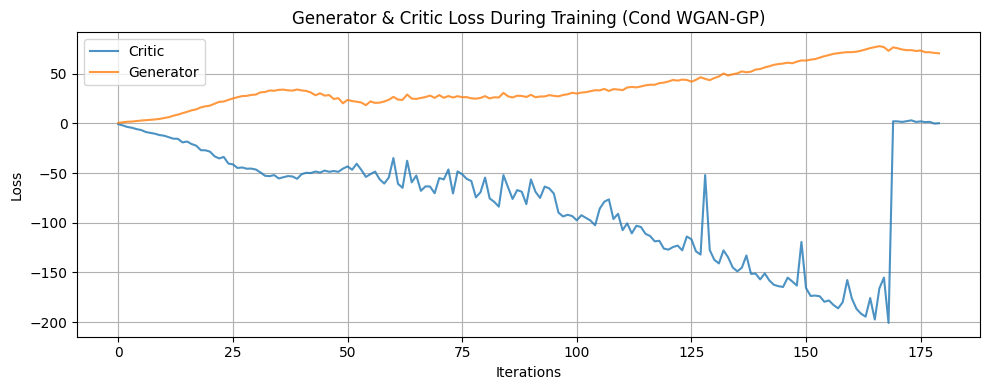

In [10]:
def plot_losses(g_losses, c_losses):
    plt.figure(figsize=(10, 4))
    plt.title("Generator & Critic Loss During Training (Cond WGAN-GP)")
    plt.plot(c_losses, label="Critic",    alpha=0.8)
    plt.plot(g_losses, label="Generator", alpha=0.8)
    plt.xlabel("Iterations")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_losses(g_losses, c_losses)

## 10. Générer des images avec un label choisi

- `label=1` → visages blonds (`Blond_Hair = 1`)
- `label=0` → visages non-blonds

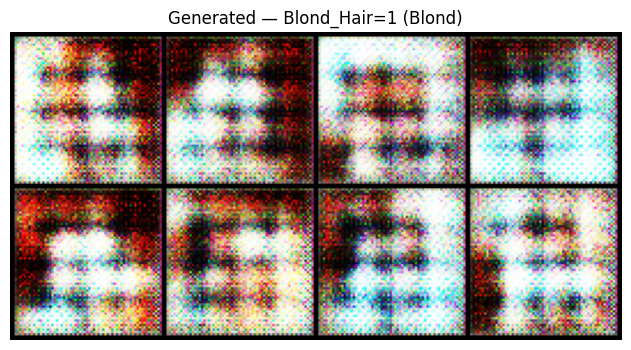

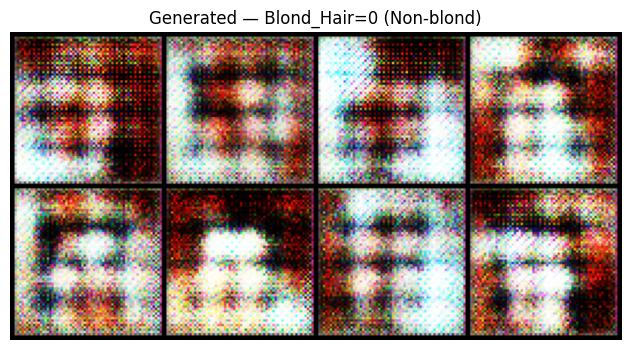

In [11]:
# -----------------------------
# GENERATE SAMPLES
# -----------------------------
def generate_samples(generator, label, num_samples=8):
    """
    Génère num_samples images pour un label donné (0 ou 1).
    """
    generator.eval()
    noise        = torch.randn(num_samples, Z_DIM, 1, 1).to(DEVICE)
    label_tensor = torch.tensor([label] * num_samples, device=DEVICE)

    with torch.no_grad():
        fake_imgs = generator(noise, label_tensor)
    fake_imgs = fake_imgs.cpu() * 0.5 + 0.5   # [-1,1] → [0,1]

    grid_img = torchvision.utils.make_grid(fake_imgs, nrow=4)
    plt.figure(figsize=(8, 4))
    plt.imshow(grid_img.permute(1, 2, 0).numpy())
    plt.axis("off")
    attr_str = "Blond" if label == 1 else "Non-blond"
    plt.title(f"Generated — {LABEL}={label} ({attr_str})")
    plt.show()
    generator.train()

generate_samples(generator, label=1, num_samples=8)   # Blond
generate_samples(generator, label=0, num_samples=8)   # Non-blond

## 11. Sauvegarder les modèles

In [12]:
torch.save(generator.state_dict(), "cond_wgan_generator.pth")
torch.save(critic.state_dict(),    "cond_wgan_critic.pth")
print("Models saved: cond_wgan_generator.pth, cond_wgan_critic.pth")

Models saved: cond_wgan_generator.pth, cond_wgan_critic.pth


## 12. Améliorations possibles (optionnel)

- **Plus de classes** : utiliser plusieurs attributs simultanément (couleur des cheveux, sourire, lunettes...)
- **Plus de profondeur** : ajouter des couches conv pour des images plus nettes
- **Image plus grande** : 128×128 ou 256×256 avec un GPU
- **Spectral Norm** dans le critic pour remplacer le BatchNorm (plus stable)